# Predecir los intereses de un cliente con una red neuronal

**Evaluación Parcial N°1 — Deep Learning (DLY0100)**

· Integrantes:

· Alberto Rincon

· Genesis Caceres

## ¿De qué trata este trabajo?

Una tienda online guarda datos de sus clientes: cuánto tiempo pasan en la página, cuántas páginas ven, cuánto han comprado, etc. Queremos que un programa **aprenda, a partir de esos datos, a adivinar si a un cliente le interesa la tecnología, la moda y/o los deportes**.

Ese programa se llama **red neuronal**. Aprende igual que un niño que aprende a reconocer perros: se le muestran muchos ejemplos con la respuesta correcta hasta que empieza a acertar también con ejemplos nuevos.

Un cliente puede tener **varios intereses a la vez, o ninguno**. Por eso la red da **3 respuestas de sí/no**, una por cada interés (a esto se le llama clasificación *multi-etiqueta*):

| Respuesta de la red | Qué significa |
|---|---|
| `[1, 0, 1]` | Le interesan la tecnología y los deportes (1 = sí, 0 = no) |
| `[0, 0, 1]` | Solo le interesan los deportes |
| `[0, 0, 0]` | No le interesa ninguna de las tres |

## Mini-glosario (para entender el resto)

| Palabra | Qué significa en simple |
|---|---|
| **Entrenar** | Mostrarle a la red muchos clientes con su respuesta correcta para que aprenda. |
| **Época** | Una vuelta completa por todos los clientes de entrenamiento. |
| **Error o pérdida** | Un número que dice cuánto se equivoca la red. **Mientras más bajo, mejor.** |
| **Entrenamiento, validación y prueba** | Tres grupos de clientes: los *ejercicios* para practicar, un *ensayo* para comparar opciones y el *examen final*. |
| **Sobreajuste** | Cuando la red aprende "de memoria" los ejemplos de práctica y luego falla con clientes nuevos. |
| **F1** | Una nota de 0 a 1 que dice qué tan bien acierta la red un interés. **1 es perfecto.** |
| **AUC** | Otra nota (de 0,5 a 1) que dice si la red distingue a los clientes que sí tienen un interés de los que no. **0,5 equivale a lanzar una moneda.** |

## Cómo leer este documento

Después de cada código hay una explicación con tres partes: **qué muestra** (qué se ve en el resultado), **qué significa** (qué quiere decir, en simple) y **qué decidimos y por qué**.

> Los números salen de una ejecución del notebook. Si se ejecuta de nuevo pueden variar un poco en el tercer decimal, pero las conclusiones son las mismas.

## 1. Preparar las herramientas y cargar los datos

Primero traemos las "herramientas" (librerías) que vamos a usar: una para manejar tablas (pandas), otras para hacer gráficos (matplotlib y seaborn), otra para preparar los datos y medir resultados (scikit-learn) y otra para construir la red neuronal (TensorFlow/Keras).

Luego cargamos `dataset.csv`, una tabla con **un cliente por fila**. Las columnas se separan en dos grupos: las **10 que usamos para predecir** (edad, tiempo de sesión, etc.) y las **3 que queremos adivinar** (los tres intereses).

También fijamos una **semilla**. La red parte con números al azar; la semilla hace que el azar sea siempre el mismo, así los resultados se repiten cada vez que se ejecuta.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, multilabel_confusion_matrix, f1_score, roc_auc_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)
sns.set_theme(style="whitegrid")

# Carga del archivo
try:
    from google.colab import files
    databaseFile = files.upload()
    for fn in databaseFile.keys():
        readedData = fn
except ImportError:                      # fuera de Colab se lee de la carpeta
    readedData = "dataset.csv"

df = pd.read_csv(readedData, sep=None, engine="python")
print("Dimensiones:", df.shape)
display(df.head())

# 3 columnas que queremos predecir (Y) y 10 columnas para predecir (X)
ETIQUETAS = ["interes_tecnologia", "interes_moda", "interes_deportes"]
NOMBRES = ["Tecnología", "Moda", "Deportes"]
VARIABLES = [c for c in df.columns if c not in ETIQUETAS]

Dimensiones: (2660, 13)


,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
0,0.473008,-2.015216,-0.617204,1.912964,1.104647,7.124469,-2.477666,-0.135015,-0.542116,-0.761970,0,1,1
1,0.578279,0.967299,1.443789,0.993972,-0.620909,-0.667771,-1.835993,-4.181187,1.502827,-1.455356,1,0,0
2,0.101556,-0.773922,-0.164761,0.464491,2.402765,-1.150528,0.157838,0.322459,-0.268127,0.219723,1,0,1
3,-0.091381,-1.361323,2.749614,-1.941579,-0.092780,-3.207476,-1.517199,1.829656,0.880481,-0.589325,0,1,0
4,1.953657,1.248484,1.212312,0.515772,-0.559830,-0.907930,113.927263,1.052013,0.281696,NaN,1,0,1


## 2. Mirar los datos antes de usarlos

Antes de enseñarle algo a la red, hay que revisar los datos, igual que se revisan los ingredientes antes de cocinar. Buscamos problemas como datos vacíos o valores raros. Cada problema que encontremos nos obligará a tomar una decisión.

### 2.1 Datos vacíos y valores extraños

Filas con al menos un dato faltante: 1056 de 2660
edad                     133
tiempo_sesion            133
paginas_vistas           133
historial_compras        133
descuentos_usados        133
dispositivo_movil        133
valoracion_media         133
frecuencia_devolucion    133
clics_publicidad         133
interaccion_redes        133


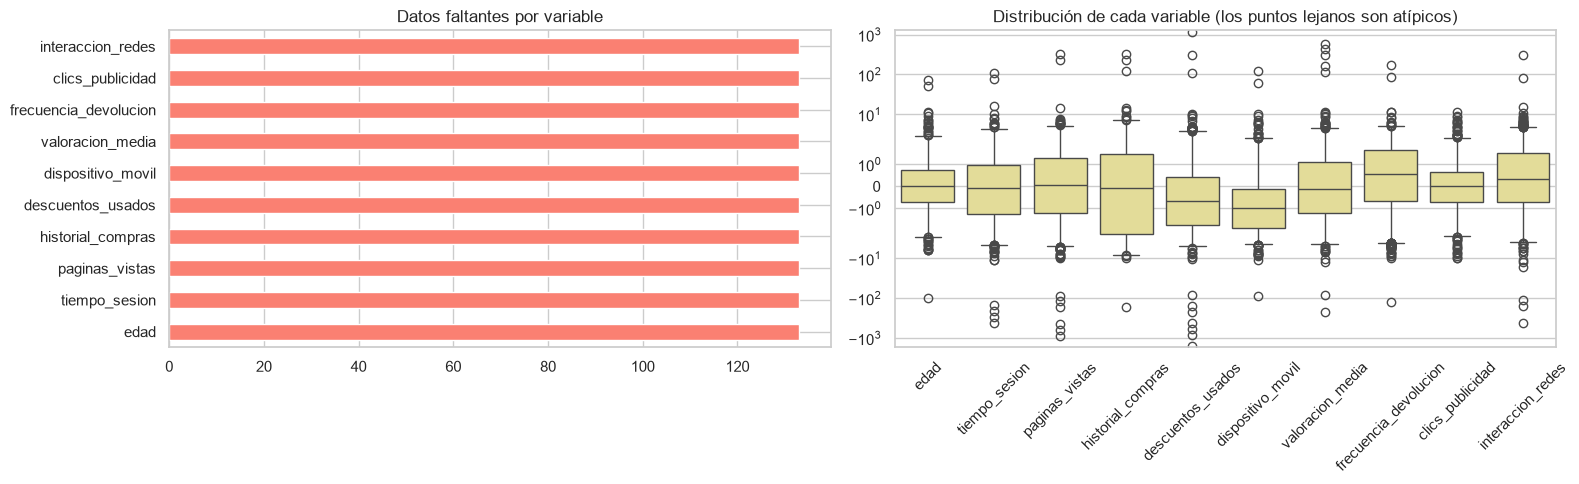

,mean,std,min,max
edad,0.03,2.86,-98.15,70.53
tiempo_sesion,-0.51,11.66,-407.86,108.17
paginas_vistas,-0.67,25.18,-880.98,325.95
historial_compras,-0.07,9.29,-167.61,324.44
descuentos_usados,-1.50,45.25,-1584.22,1135.57
dispositivo_movil,-0.96,3.58,-89.61,122.43
valoracion_media,0.50,17.08,-221.06,597.60
frecuencia_devolucion,0.46,4.88,-121.33,170.02
clics_publicidad,-0.01,1.20,-9.72,11.62
interaccion_redes,0.32,11.50,-429.83,309.45


In [2]:
print("Filas con al menos un dato faltante:", df.isna().any(axis=1).sum(), "de", len(df))
print(df[VARIABLES].isna().sum().to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df[VARIABLES].isna().sum().plot(kind="barh", color="salmon", ax=axes[0], title="Datos faltantes por variable")
sns.boxplot(data=df[VARIABLES], color="khaki", ax=axes[1])
axes[1].set_yscale("symlog")             # escala que permite ver valores muy grandes y chicos a la vez
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Distribución de cada variable (los puntos lejanos son atípicos)")
plt.tight_layout()
plt.show()

display(df[VARIABLES].describe().T[["mean", "std", "min", "max"]].round(2))

> **Qué muestra:** el gráfico de barras (izquierda) cuenta los **datos vacíos**: cada columna tiene 133 (un 5%). Parece poco, pero están en clientes distintos, así que **1.056 de los 2.660 clientes (casi 4 de cada 10) tienen al menos un dato vacío**. El gráfico de cajas (derecha) muestra el rango de valores de cada columna: los puntos sueltos lejos de las cajas son **valores extraños**. Por ejemplo, `descuentos_usados` llega a −1.584 y a 1.135, `paginas_vistas` llega a −881 y `valoracion_media` a 597, cuando casi todos los demás valores están entre −5 y 5. En la tabla, la columna `std` mide qué tan dispersos están los datos: `descuentos_usados` tiene 45, mientras que `clics_publicidad` tiene solo 1,2.
>
> **Qué significa:** un cliente no puede haber usado "−1.584 descuentos". Esos valores son **errores de registro**. Los llamamos **valores atípicos**: datos tan lejos del resto que casi seguro son errores. Si se los dejamos a la red, la confunden, porque tiene que intentar ajustarse a números absurdos.
>
> **Qué decidimos y por qué:** (1) **No borrar a los clientes con datos vacíos**, porque perderíamos casi la mitad de los clientes; mejor los rellenamos. (2) **Marcar los valores extraños como "vacíos"** para rellenarlos también. Así la red recibe datos limpios.

### 2.2 ¿Cuántos clientes tienen cada interés? ¿Qué datos se relacionan con ellos?

Miramos tres cosas: qué porcentaje de clientes tiene cada interés, cuántos intereses tiene cada cliente y la **correlación**.

La **correlación** es un número entre −1 y 1 que dice si dos cosas "suben y bajan juntas". Cerca de 1 (o de −1) la relación es fuerte; cerca de 0 no hay relación. Ejemplo: la estatura y el peso de las personas tienen una correlación alta; la estatura y el número de calzado de tu vecino, cercana a 0.

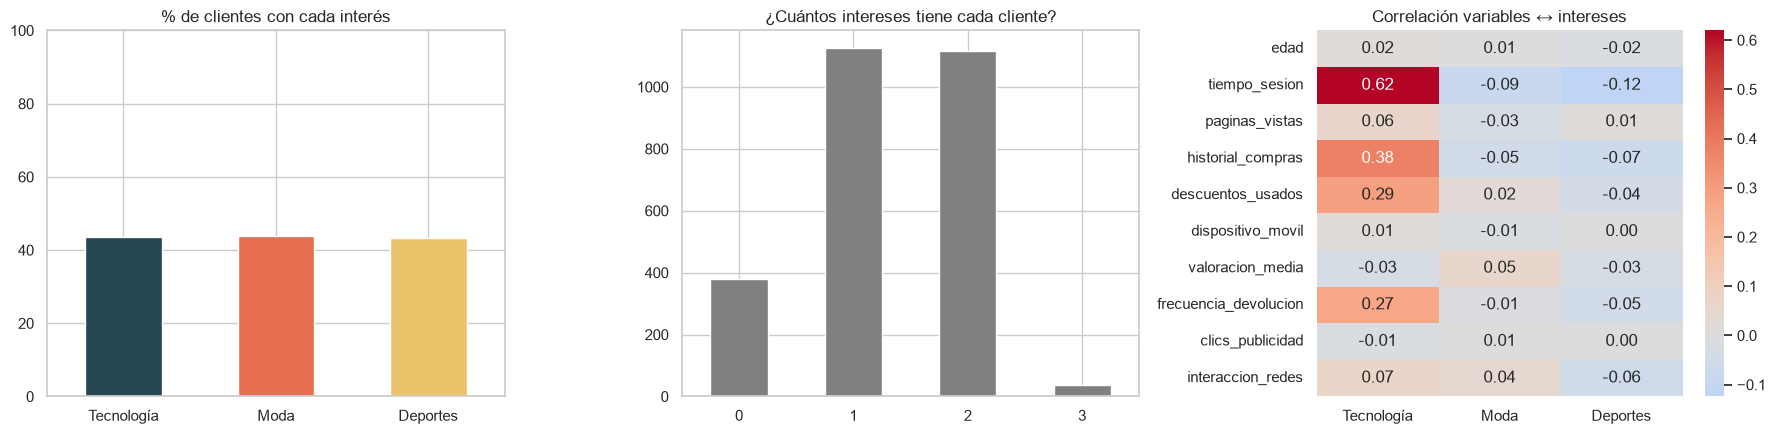

0     380
1    1126
2    1116
3      38


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
df[ETIQUETAS].mean().mul(100).plot(kind="bar", ax=axes[0], color=["#264653", "#e76f51", "#e9c46a"], rot=0)
axes[0].set_xticklabels(NOMBRES); axes[0].set_ylim(0, 100); axes[0].set_title("% de clientes con cada interés")
df[ETIQUETAS].sum(axis=1).value_counts().sort_index().plot(kind="bar", ax=axes[1], color="gray", rot=0)
axes[1].set_title("¿Cuántos intereses tiene cada cliente?")
sns.heatmap(df.corr(method="spearman").loc[VARIABLES, ETIQUETAS], annot=True, fmt=".2f", cmap="coolwarm",
            center=0, xticklabels=NOMBRES, ax=axes[2])
axes[2].set_title("Correlación variables ↔ intereses")
plt.tight_layout()
plt.show()

print(df[ETIQUETAS].sum(axis=1).value_counts().sort_index().to_string())

> **Qué muestra:** *Izquierda:* los tres intereses están casi al mismo nivel, lo que quiere decir que son igual de comunes en un 44% de cada uno. *Centro:* 380 clientes no tienen ningún interés, 1.126 tienen uno, 1.116 tienen dos y solo 38 tienen los tres. *Derecha (mapa de colores):* cuánto se relaciona cada dato con cada interés; mientras más intenso el color, más fuerte la relación. Solo **tecnología** tiene relaciones claras: con `tiempo_sesion` (0,62), `historial_compras` (0,38) y `descuentos_usados` (0,29). **Moda y deportes** casi no se relacionan con ningún dato (números cerca de 0).
>
> **Qué significa:** (1) Como hay clientes con 0, 1 o 2 intereses, no sirve una red que "elija solo una opción": necesitamos una que responda sí/no a cada interés por separado. (2) Ningún interés es escaso, están parejos. (3) Ya podemos anticipar que **tecnología será fácil de adivinar y moda y deportes difíciles**, porque los datos casi no dan pistas sobre ellos.
>
> **Qué decidimos y por qué:** la red tendrá **3 respuestas, una por interés**, cada una un sí/no. **No usamos SMOTE**, una técnica del ejemplo de clase que fabrica ejemplos de un grupo muy pequeño: aquí ningún interés es escaso, así que no hace falta.

## 3. Preparar los datos para la red

**Paso 1: separar los datos en tres grupos**, como en el colegio:
- **70% entrenamiento:** los ejercicios con los que la red practica.
- **15% validación:** un ensayo que usamos para comparar opciones y elegir la mejor.
- **15% prueba:** el examen final. Solo se usa **al final**, con clientes que la red nunca ha visto.

**Paso 2: limpiar los datos**, en tres partes:
1. **Valores extraños → vacíos.** Una parte central de los datos (el 50% del medio) ocupa un cierto rango; a su ancho lo llamamos *IQR*. Si un valor está a más de 3 veces ese ancho fuera del rango central, lo consideramos un error y lo marcamos como vacío.
2. **Rellenar los vacíos con la mediana.** La mediana es el valor del medio cuando se ordenan los datos. La usamos en vez del promedio porque un valor gigante no la mueve.
3. **Escalar.** Ponemos todas las columnas en la misma escala (promedio 0). Es como pasar todo a la misma unidad: si una columna llega a miles y otra a decenas, la red le haría más caso a la grande solo por tener números más grandes.

**Una regla importante:** la mediana, los límites y la escala se calculan **solo con los datos de entrenamiento**. Si usáramos también los de prueba sería **hacer trampa**, como mirar las preguntas del examen antes de rendirlo. A esa trampa se le llama *data leakage* ("filtración de datos").

Entrenamiento: (1861, 10) | Validación: (400, 10) | Prueba: (399, 10)
Atípicos encontrados en entrenamiento: 95


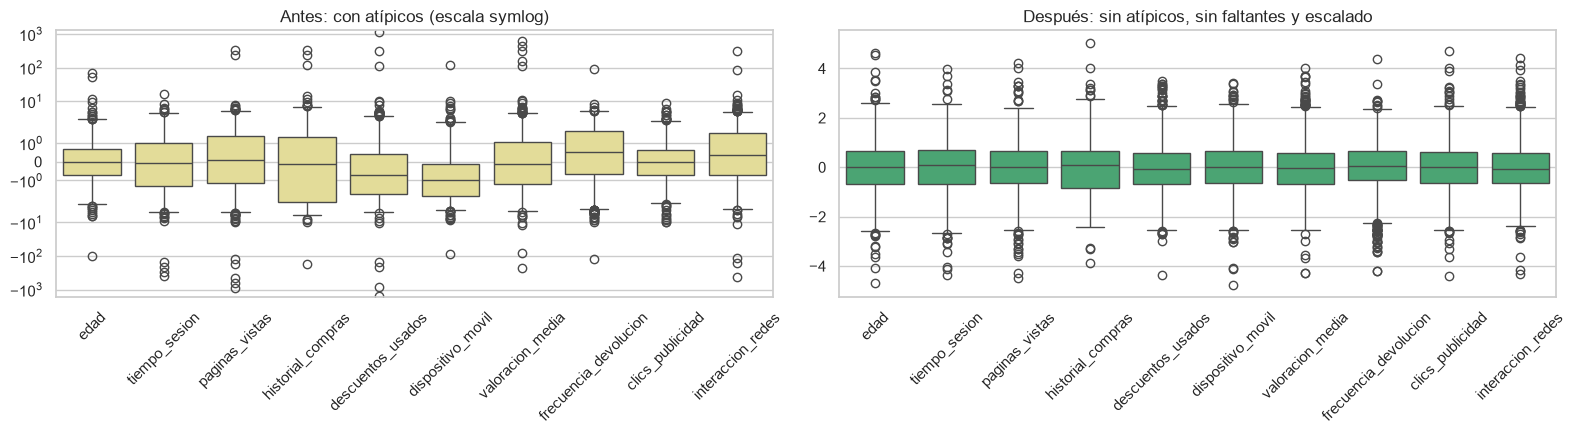

In [4]:
X = df[VARIABLES]
Y = df[ETIQUETAS].values

# 70% entrenamiento, 15% validación, 15% prueba
X_temp, X_test, Y_temp, Y_test = train_test_split(X, Y, test_size=0.15, random_state=42)
X_train, X_val, Y_train, Y_val = train_test_split(X_temp, Y_temp, test_size=0.1765, random_state=42)

# 1) Límites de atípicos (regla IQR), calculados SOLO con entrenamiento
Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
limite_inf, limite_sup = Q1 - 3 * IQR, Q3 + 3 * IQR

def atipicos_a_nan(datos):
    return datos.mask((datos < limite_inf) | (datos > limite_sup))

# 2) Rellenar con la mediana  y  3) escalar (el "fit" se hace SOLO con entrenamiento)
imputador, escalador = SimpleImputer(strategy="median"), StandardScaler()
X_train_limpio = escalador.fit_transform(imputador.fit_transform(atipicos_a_nan(X_train)))
X_val_limpio = escalador.transform(imputador.transform(atipicos_a_nan(X_val)))
X_test_limpio = escalador.transform(imputador.transform(atipicos_a_nan(X_test)))

# Versión SIN quitar atípicos (solo para comparar más adelante)
imp2, esc2 = SimpleImputer(strategy="median"), StandardScaler()
X_train_sucio = esc2.fit_transform(imp2.fit_transform(X_train))
X_val_sucio = esc2.transform(imp2.transform(X_val))

print("Entrenamiento:", X_train.shape, "| Validación:", X_val.shape, "| Prueba:", X_test.shape)
print("Atípicos encontrados en entrenamiento:", int(((X_train < limite_inf) | (X_train > limite_sup)).sum().sum()))

# Gráfico: antes y después de la limpieza
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=X_train, color="khaki", ax=axes[0]); axes[0].set_yscale("symlog")
axes[0].set_title("Antes: con atípicos (escala symlog)")
sns.boxplot(data=pd.DataFrame(X_train_limpio, columns=VARIABLES), color="mediumseagreen", ax=axes[1])
axes[1].set_title("Después: sin atípicos, sin faltantes y escalado")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

> **Qué muestra:** en los datos de entrenamiento encontramos **95 valores extraños**. En el gráfico de la izquierda (*antes*) hay puntos hasta ±100 e incluso ±1.000, y cada columna tiene un tamaño distinto. En el de la derecha (*después*) todas las columnas son parecidas, casi todo queda entre −4 y 4, y no hay valores imposibles. Los puntos que quedan sueltos son valores algo alejados pero normales, no errores.
>
> **Qué significa:** dejamos todas las columnas "en el mismo idioma": sin datos vacíos, sin errores y con la misma escala. Así la red no le da más importancia a una columna solo porque sus números son más grandes.
>
> **Qué decidimos y por qué:** usamos esta limpieza (regla del IQR, mediana y escala estándar) calculada **solo con los datos de entrenamiento**, para no hacer trampa. En la vida real la red recibirá clientes nuevos que no conoce; los grupos de validación y prueba hacen de "clientes nuevos".

## 4. La red neuronal

**¿Cómo es una red neuronal?** Es una cadena de **capas**. Cada capa tiene **neuronas**, que son pequeñas calculadoras: reciben números, los combinan y pasan el resultado a la siguiente capa. La primera capa recibe los 10 datos del cliente y la última entrega la respuesta.

**¿Por qué la última capa tiene 3 neuronas con función *sigmoid*?** Cada neurona de salida da un número entre 0 y 1 (una especie de probabilidad): ¿le interesa la tecnología?, ¿la moda?, ¿los deportes? Si el número pasa de 0,5, la respuesta es "sí". Cada neurona decide **por separado**, así un cliente puede recibir varios "sí" o ninguno.

La otra opción, *softmax*, haría que las tres probabilidades **sumaran 100%**, como repartir una torta: si una sube, otra baja, y solo una puede ganar. No sirve cuando a un cliente le pueden gustar dos cosas a la vez. Por eso usamos sigmoid, junto con la medida de error `binary_crossentropy`, que está hecha justamente para preguntas de sí/no.

**La función `crear_modelo`:** como vamos a probar muchas versiones de la red, escribimos su "receta" una sola vez. Es la red del ejemplo de clase (2 capas del medio, de 64 y 32 neuronas) pero con 3 salidas. *Dropout* y *L2* son técnicas para que la red no memorice; las explicamos en la sección 5.6.

**`config`** es un diccionario donde guardamos la configuración actual. Cada experimento cambia una sola opción y, al final, anotamos ahí la mejor.

In [5]:
def crear_modelo(capas=[64, 32], activacion="relu", dropout=0.2, valor_l2=0.001,
                 learning_rate=0.001, perdida="binary_crossentropy"):
    model = Sequential()
    model.add(Input(shape=(len(VARIABLES),)))                 # 10 variables de entrada
    for neuronas in capas:                                    # capas ocultas
        model.add(Dense(neuronas, activation=activacion, kernel_regularizer=l2(valor_l2)))
        if dropout > 0:
            model.add(Dropout(dropout))                       # apaga neuronas al azar al entrenar
    model.add(Dense(3, activation="sigmoid"))                 # 3 salidas: una por interés
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss=perdida, metrics=["binary_accuracy"])
    return model

# Configuración actual (al principio es la de clase). Cada experimento actualiza una opción.
config = dict(capas=[64, 32], activacion="relu", dropout=0.2, valor_l2=0.001,
              learning_rate=0.001, perdida="binary_crossentropy")
BATCH = 32
COLUMNAS = ["Configuración", "val_loss final", "F1 Tecnología", "F1 Moda", "F1 Deportes", "F1 promedio"]

### 4.1 Primera red: la del ejemplo de clase

Entrenamos la red con la misma configuración del ejemplo del profesor, para tener un **punto de comparación**. Entrenar 50 épocas significa que la red repasa 50 veces a todos los clientes de entrenamiento.

**¿Qué son los 2.883 parámetros?** Son los números internos que la red ajusta mientras aprende (como las perillas de una radio). Se calculan así: (10 entradas × 64 neuronas + 64) + (64 × 32 + 32) + (32 × 3 + 3) = 704 + 2.080 + 99.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,883 (11.26 KB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 0 (0.00 B)

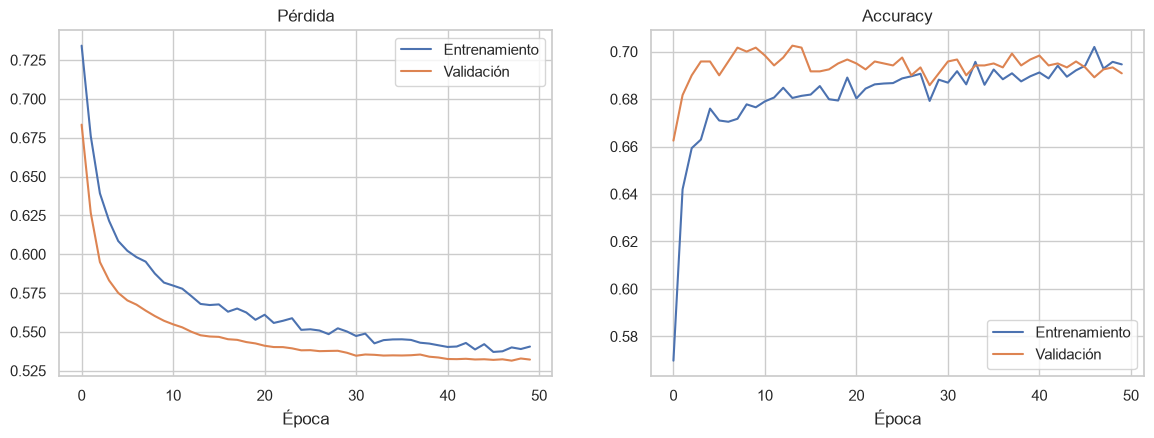

val_loss final: 0.532 | F1 por interés: [0.908 0.384 0.362] | promedio: 0.551


In [6]:
tf.keras.utils.set_random_seed(42)
modelo_base = crear_modelo(**config)
modelo_base.summary()
historia_base = modelo_base.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val),
                                epochs=50, batch_size=BATCH, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(historia_base.history["loss"], label="Entrenamiento")
axes[0].plot(historia_base.history["val_loss"], label="Validación")
axes[0].set_title("Pérdida"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(historia_base.history["binary_accuracy"], label="Entrenamiento")
axes[1].plot(historia_base.history["val_binary_accuracy"], label="Validación")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Época"); axes[1].legend()
plt.show()

f1 = f1_score(Y_val, (modelo_base.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
print("val_loss final:", round(historia_base.history["val_loss"][-1], 3), "| F1 por interés:", f1.round(3), "| promedio:", f1.mean().round(3))

Qué muestra: Arriba, la tabla es el plano de la red: una capa de 64 neuronas, otra de 32 y una salida de 3 (una por interés), con capas Dropout entre medio. En total tiene 2.883 parámetros, los números que la red ajusta al aprender. Abajo hay dos gráficos. A la izquierda, el error (pérdida): baja rápido en las primeras 10 épocas y después casi no cambia, tanto en entrenamiento (azul) como en validación (naranja). A la derecha, el porcentaje de aciertos (accuracy), que se estabiliza cerca de 0,69. Los gráficos juntan los tres intereses en un solo número, así que para verlos por separado imprimimos la nota F1 de cada uno: 0,91 en tecnología, 0,38 en moda y 0,36 en deportes (promedio 0,55). El error final de validación es 0,532.

Qué significa: la red aprende rápido lo que puede y después se estanca. Las dos curvas se mantienen juntas, así que no está memorizando. La naranja queda un poco por debajo de la azul porque el Dropout apaga neuronas solo mientras entrena, como practicar con una mano atada. Al evaluar usa todas sus neuronas y le va algo mejor. El accuracy de 0,69 engaña, porque mezcla un interés que la red adivina muy bien (tecnología) con dos que adivina mal (moda y deportes). Por eso usamos la nota F1 de cada interés.

Qué decidimos y por qué: usar esta red, igual a la del ejemplo de clase y construida con Keras (la parte de TensorFlow que permite armar redes neuronales de forma sencilla), como punto de comparación. En cada experimento siguiente cambiamos una sola cosa y vemos si mejora o empeora respecto a estos números


### 4.2 ¿De verdad sirvió limpiar los datos?

Entrenamos la misma red con datos **sin** quitar los valores extraños y comparamos los resultados.

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,Con limpieza,0.532,0.908,0.384,0.362,0.551
1,Sin quitar atípicos,0.602,0.860,0.159,0.341,0.453


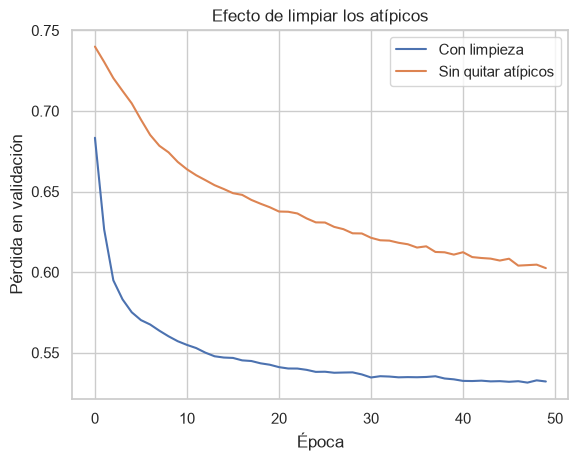

In [7]:
datos = {"Con limpieza": (X_train_limpio, X_val_limpio), "Sin quitar atípicos": (X_train_sucio, X_val_sucio)}

tabla, historias = [], {}
for nombre, (X_tr, X_va) in datos.items():
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_tr, Y_train, validation_data=(X_va, Y_val), epochs=50, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_va, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([nombre, h.history["val_loss"][-1], *f1, f1.mean()])
    historias[nombre] = h.history

display(pd.DataFrame(tabla, columns=COLUMNAS).round(3))
for nombre, h in historias.items():
    plt.plot(h["val_loss"], label=nombre)
plt.title("Efecto de limpiar los atípicos"); plt.xlabel("Época"); plt.ylabel("Pérdida en validación"); plt.legend()
plt.show()

> **Qué muestra:** sin quitar los valores extraños, el error de validación sube de 0,532 a **0,602**, la nota F1 de tecnología baja de 0,91 a **0,86** y la de moda cae de 0,38 a **0,16**.
>
> **Qué significa:** los valores absurdos confunden a la red y aprende peor. Esto es una prueba, con números, de que limpiar los datos **sí importa**.
>
> **Qué decidimos y por qué:** mantener la limpieza. Es la decisión que más mejoró el resultado de todo el trabajo.

## 5. Experimentos: cambiar una sola cosa a la vez

Para saber qué ajustes ayudan, hacemos como en un experimento de ciencias: **cambiamos una sola cosa y dejamos todo lo demás igual**. Si el resultado cambia, sabemos exactamente por qué. Al final de cada experimento anotamos la mejor opción (línea `# DECISIÓN`) y el siguiente experimento parte desde ahí.

En cada experimento miramos dos cosas: el **error en validación** (`val_loss`: mientras más bajo, mejor) y la **nota F1 de cada interés** (mientras más alta, mejor).

### 5.1 Learning rate (tasa de aprendizaje)

Es el **tamaño de los pasos** con que la red corrige sus errores. Imagina bajar un cerro con los ojos vendados para llegar al punto más bajo: con pasos enormes te pasas de largo; con pasos diminutos te demoras demasiado.

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,lr = 0.1,0.600,0.879,0.000,0.435,0.438
1,lr = 0.01,0.539,0.899,0.215,0.263,0.459
2,lr = 0.001,0.532,0.908,0.384,0.362,0.551
3,lr = 0.0001,0.576,0.888,0.336,0.332,0.519


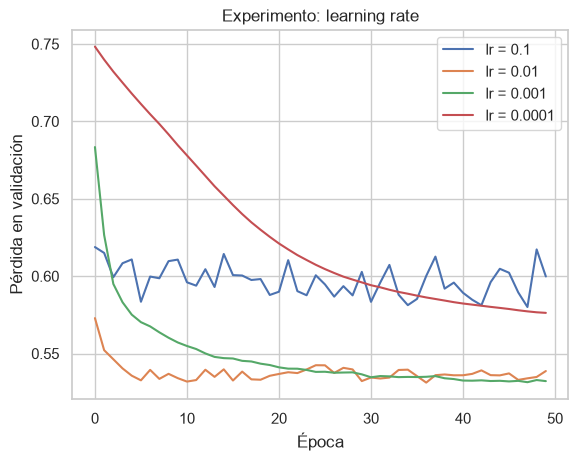

In [8]:
tabla, historias = [], {}
for lr in [0.1, 0.01, 0.001, 0.0001]:
    config["learning_rate"] = lr
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=50, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([f"lr = {lr}", h.history["val_loss"][-1], *f1, f1.mean()])
    historias[f"lr = {lr}"] = h.history

display(pd.DataFrame(tabla, columns=COLUMNAS).round(3))
for nombre, h in historias.items():
    plt.plot(h["val_loss"], label=nombre)
plt.title("Experimento: learning rate"); plt.xlabel("Época"); plt.ylabel("Pérdida en validación"); plt.legend()
plt.show()

config["learning_rate"] = 0.001      # DECISIÓN (ver explicación)

> **Qué muestra:** cada línea es una red con un tamaño de paso distinto. Con **0,1** el error de validación es 0,600 y la nota F1 de moda cae a **0** (nunca acierta ese interés). Con 0,01 el error es 0,539; con **0,001** es **0,532** (el más bajo); con 0,0001 es 0,576.
>
> **Qué significa:** con 0,1 los pasos son tan grandes que la red se pasa de largo y termina respondiendo "no" a todos en moda. Con 0,0001 son tan pequeños que en 50 vueltas no alcanza a aprender todo. Un paso mediano funciona mejor.
>
> **Qué decidimos y por qué:** **learning rate = 0,001**, porque tiene el error más bajo y la mejor nota F1 promedio (0,551).

### 5.2 Tamaño del batch

Es **cuántos clientes mira la red antes de corregirse**. Con un batch chico (16) se corrige muy seguido, pero se demora más. Con un batch grande (128) se corrige menos veces y es más rápido.

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,batch = 16,0.534,0.908,0.338,0.410,0.552
1,batch = 32,0.532,0.908,0.384,0.362,0.551
2,batch = 128,0.540,0.917,0.332,0.376,0.542


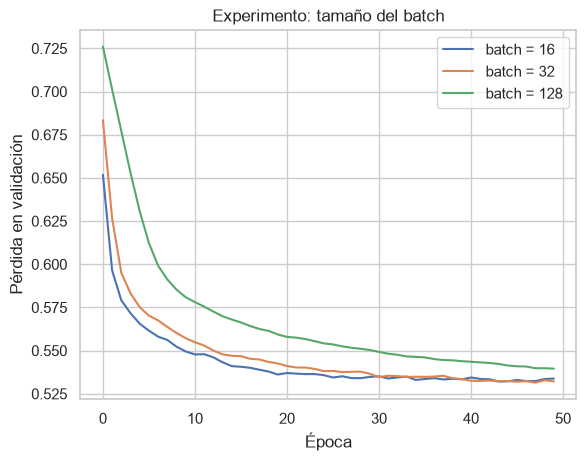

In [9]:
tabla, historias = [], {}
for batch in [16, 32, 128]:
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=50, batch_size=batch, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([f"batch = {batch}", h.history["val_loss"][-1], *f1, f1.mean()])
    historias[f"batch = {batch}"] = h.history

display(pd.DataFrame(tabla, columns=COLUMNAS).round(3))
for nombre, h in historias.items():
    plt.plot(h["val_loss"], label=nombre)
plt.title("Experimento: tamaño del batch"); plt.xlabel("Época"); plt.ylabel("Pérdida en validación"); plt.legend()
plt.show()

BATCH = 32      # DECISIÓN (ver explicación)

> **Qué muestra:** las tres líneas casi se superponen. Los errores son 0,534 (batch 16), **0,532** (batch 32) y 0,540 (batch 128), y el F1 promedio es 0,552, 0,551 y 0,542.
>
> **Qué significa:** en este problema el tamaño del batch **casi no importa**. Lo que cambia es el tiempo que demora el entrenamiento.
>
> **Qué decidimos y por qué:** **batch = 32**, porque tiene el error más bajo y es un valor típico. El de 16 empata en F1 pero se demora más.

### 5.3 Número de épocas

Una **época** es una vuelta completa por todos los clientes de entrenamiento. ¿Cuántas vueltas conviene dar? Entrenamos 150 para ver **en qué momento la red deja de mejorar**.

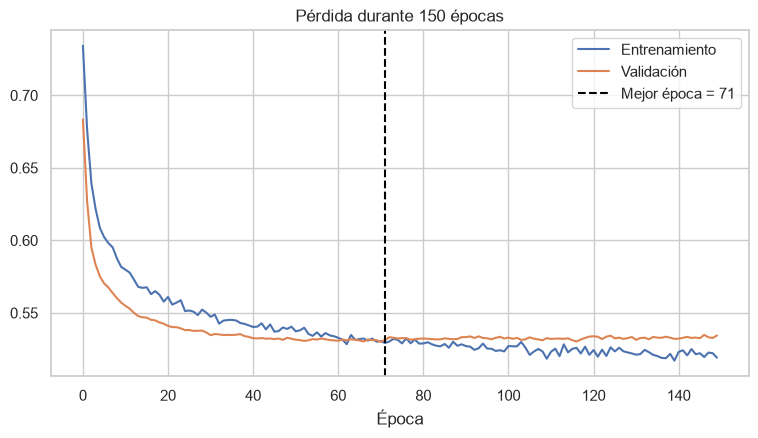

La pérdida de validación fue mínima en la época 71


In [10]:
tf.keras.utils.set_random_seed(42)
model = crear_modelo(**config)
h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=150, batch_size=BATCH, verbose=0)
mejor_epoca = int(np.argmin(h.history["val_loss"])) + 1

plt.figure(figsize=(9, 4.5))
plt.plot(h.history["loss"], label="Entrenamiento")
plt.plot(h.history["val_loss"], label="Validación")
plt.axvline(mejor_epoca, color="black", ls="--", label=f"Mejor época = {mejor_epoca}")
plt.title("Pérdida durante 150 épocas"); plt.xlabel("Época"); plt.legend()
plt.show()
print("La pérdida de validación fue mínima en la época", mejor_epoca)

> **Qué muestra:** la línea azul es el entrenamiento y la naranja la validación. El error de validación baja hasta la **época 71** y después se queda plano, mientras que el de entrenamiento sigue bajando. La línea negra marca la mejor época.
>
> **Qué significa:** pasada la época 71, la red empieza a **memorizar** a los clientes de entrenamiento en vez de aprender reglas generales: sigue mejorando con los clientes que ya vio, pero ya no mejora con clientes nuevos. Es como estudiar de memoria las respuestas de un libro: te va cada vez mejor con esos ejercicios, pero no aprendes nada nuevo para la prueba. Eso se llama **sobreajuste**. Aquí es leve, gracias a la regularización (Dropout y L2), pero muestra que seguir entrenando no ayuda.
>
> **Qué decidimos y por qué:** en la red final usamos **EarlyStopping** ("parada temprana"): el entrenamiento se detiene solo cuando, durante 10 épocas seguidas, la red no mejora, y se queda con la mejor versión. Así no tenemos que adivinar cuántas vueltas dar.

### 5.4 Función de activación (capas del medio)

Cada neurona de las capas del medio decide **cuánta señal pasa** a la siguiente capa. Esa regla se llama *función de activación*. Comparamos dos:
- **ReLU:** si el número es negativo lo convierte en 0; si es positivo lo deja igual.
- **tanh:** convierte cualquier número en uno entre −1 y 1. El problema es que se "aplana" en los extremos: ahí casi no cambia, la red recibe poca información para corregirse y aprende más lento.

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,relu,0.532,0.908,0.384,0.362,0.551
1,tanh,0.546,0.881,0.263,0.317,0.487


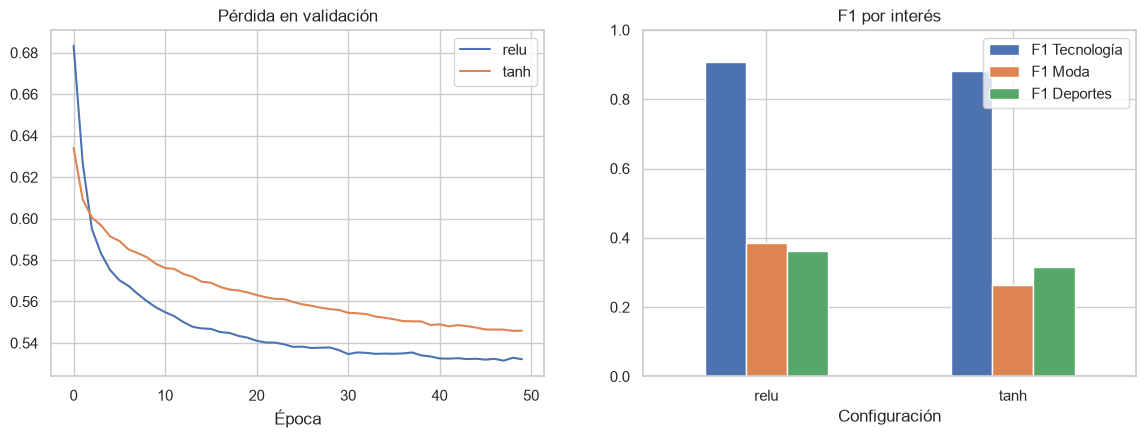

In [11]:
tabla, historias = [], {}
for act in ["relu", "tanh"]:
    config["activacion"] = act
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=50, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([act, h.history["val_loss"][-1], *f1, f1.mean()])
    historias[act] = h.history

tabla_act = pd.DataFrame(tabla, columns=COLUMNAS)
display(tabla_act.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, h in historias.items():
    axes[0].plot(h["val_loss"], label=nombre)
axes[0].set_title("Pérdida en validación"); axes[0].set_xlabel("Época"); axes[0].legend()
tabla_act.set_index("Configuración")[["F1 Tecnología", "F1 Moda", "F1 Deportes"]].plot(kind="bar", rot=0, ax=axes[1])
axes[1].set_title("F1 por interés"); axes[1].set_ylim(0, 1)
plt.show()

config["activacion"] = "relu"      # DECISIÓN (ver explicación)

> **Qué muestra:** *Izquierda:* el error de validación en cada vuelta. *Derecha:* la nota F1 de cada interés en barras. Con **ReLU** el error es 0,532 y el F1 promedio 0,55; con **tanh** el error es 0,546 y el F1 promedio 0,49. En moda, el F1 baja de 0,38 a 0,26.
>
> **Qué significa:** ReLU aprende mejor y gana en los tres intereses, tal como se esperaba por cómo funciona tanh.
>
> **Qué decidimos y por qué:** **ReLU** para las capas del medio. (La función sigmoid sí se usa en la última capa, porque ahí necesitamos probabilidades entre 0 y 1; este experimento era solo para las capas del medio.)

### 5.5 Función de pérdida (la medida del error)

Es la "regla" que mide **cuánto se equivoca** la red; la red intenta que ese número sea lo más bajo posible. Comparamos dos:
- **binary_crossentropy:** está hecha para preguntas de sí/no y castiga muchísimo equivocarse estando muy seguro.
- **mse (error cuadrático medio):** promedia el tamaño de los errores. Se usa normalmente para predecir números, como un precio.

Como miden con reglas distintas, **no se pueden comparar sus errores directamente** (sería como comparar pesos con dólares). Por eso comparamos la nota F1.

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,binary_crossentropy,0.532,0.908,0.384,0.362,0.551
1,mse,0.187,0.905,0.299,0.365,0.523


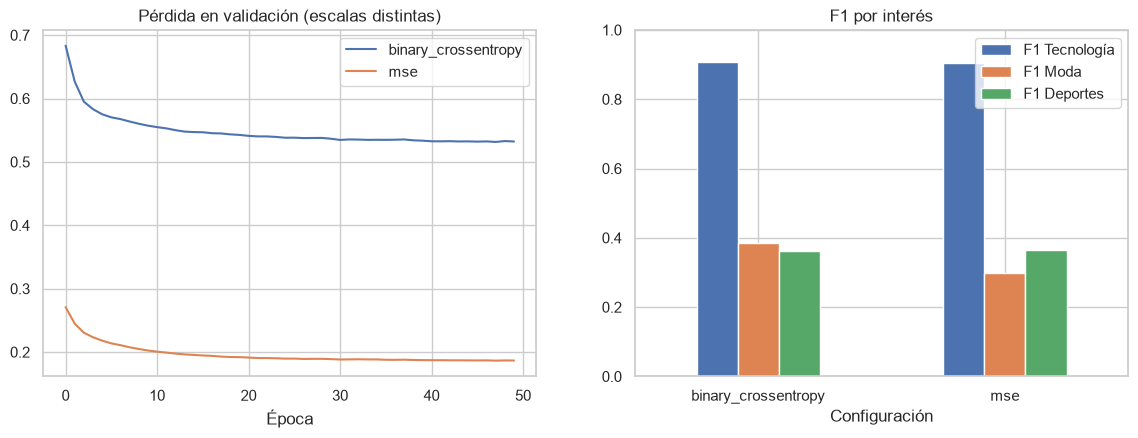

In [12]:
tabla, historias = [], {}
for perdida in ["binary_crossentropy", "mse"]:
    config["perdida"] = perdida
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=50, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([perdida, h.history["val_loss"][-1], *f1, f1.mean()])
    historias[perdida] = h.history

tabla_perdida = pd.DataFrame(tabla, columns=COLUMNAS)
display(tabla_perdida.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, h in historias.items():
    axes[0].plot(h["val_loss"], label=nombre)
axes[0].set_title("Pérdida en validación (escalas distintas)"); axes[0].set_xlabel("Época"); axes[0].legend()
tabla_perdida.set_index("Configuración")[["F1 Tecnología", "F1 Moda", "F1 Deportes"]].plot(kind="bar", rot=0, ax=axes[1])
axes[1].set_title("F1 por interés"); axes[1].set_ylim(0, 1)
plt.show()

config["perdida"] = "binary_crossentropy"      # DECISIÓN (ver explicación)

> **Qué muestra:** *Izquierda:* dos curvas a alturas muy distintas (0,53 y 0,19). Eso **no** significa que MSE sea mejor: miden con reglas distintas y no se pueden comparar. *Derecha:* la nota F1. Tecnología queda casi igual (0,908 y 0,905), pero moda baja de **0,384 a 0,299** con MSE y el promedio baja de 0,551 a 0,523.
>
> **Qué significa:** con binary_crossentropy la red corrige con más fuerza cuando se equivoca estando segura. MSE es más suave y por eso la red aprende un poco peor.
>
> **Qué decidimos y por qué:** **binary_crossentropy**, porque está pensada para preguntas de sí/no y dio mejor F1.

### 5.6 Regularización: Dropout y L2

Son técnicas para que la red **no memorice**.
- **Dropout:** en cada paso del entrenamiento "apaga" al azar algunas neuronas, así la red no depende de unas pocas. Es como estudiar sin poder apoyarte siempre en el mismo compañero.
- **L2:** castiga a la red cuando sus números internos se hacen demasiado grandes, lo que la obliga a ser más simple.

Entrenamos 100 épocas para que se note el efecto. **Línea punteada = entrenamiento, línea continua = validación.**

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,Sin regularización,0.593,0.918,0.401,0.395,0.571
1,Dropout + L2,0.532,0.913,0.431,0.411,0.585


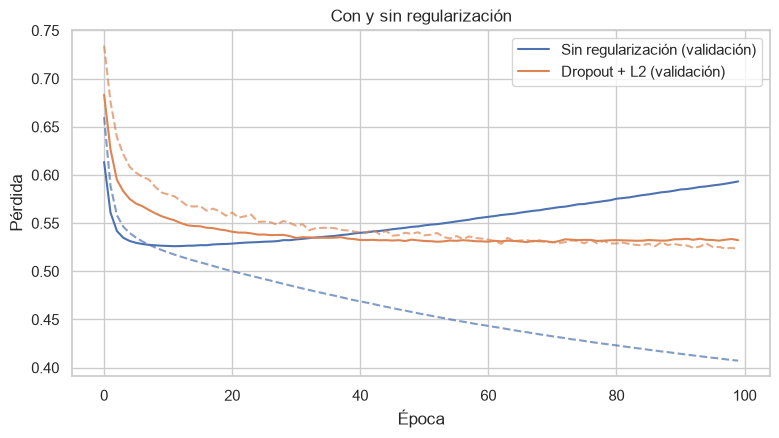

In [13]:
tabla = []
plt.figure(figsize=(9, 4.5))
for i, (nombre, (drop, valor)) in enumerate({"Sin regularización": (0, 0), "Dropout + L2": (0.2, 0.001)}.items()):
    config["dropout"], config["valor_l2"] = drop, valor
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=100, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([nombre, h.history["val_loss"][-1], *f1, f1.mean()])
    plt.plot(h.history["val_loss"], color=f"C{i}", label=f"{nombre} (validación)")
    plt.plot(h.history["loss"], color=f"C{i}", ls="--", alpha=0.7)

display(pd.DataFrame(tabla, columns=COLUMNAS).round(3))
plt.title("Con y sin regularización"); plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.legend()
plt.show()

config["dropout"], config["valor_l2"] = 0.2, 0.001      # DECISIÓN (ver explicación)

> **Qué muestra:** *Sin regularización (azul):* la línea punteada baja hasta 0,41, pero la continua **sube** desde la época 10 hasta 0,593; las dos líneas se separan. *Con Dropout + L2 (naranja):* las dos líneas quedan juntas, cerca de 0,53, hasta el final.
>
> **Qué significa:** cuando las dos líneas se separan, la red está **memorizando** (sobreajuste): le va muy bien con los clientes que ya vio y peor con clientes nuevos. La regularización la obliga a aprender reglas generales en vez de memorizar.
>
> **Qué decidimos y por qué:** **Dropout 0,2 + L2 0,001**, porque da menor error de validación (0,532 contra 0,593), mejor F1 promedio (0,585 contra 0,571) y un entrenamiento estable.

### 5.7 Cantidad de capas y neuronas

Más capas y más neuronas le dan a la red más **capacidad** para aprender cosas complicadas, pero también la hacen más lenta y más propensa a memorizar. Comparamos la red de clase (2 capas: 64 y 32 neuronas) con una más grande (3 capas).

,Configuración,val_loss final,F1 Tecnología,F1 Moda,F1 Deportes,F1 promedio
0,"2 capas [64, 32]",0.532,0.908,0.384,0.362,0.551
1,"3 capas [128, 64, 32]",0.537,0.908,0.380,0.392,0.560


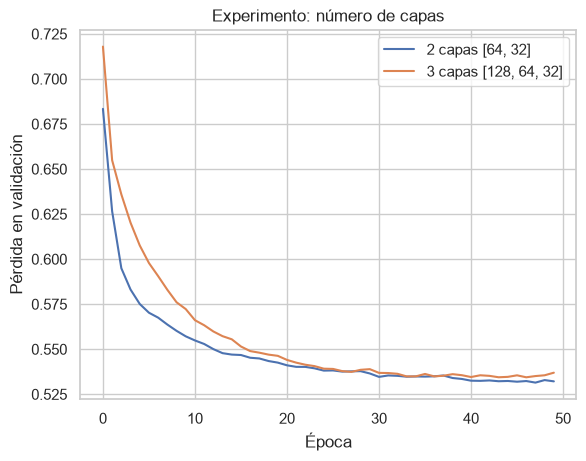

In [14]:
tabla, historias = [], {}
for nombre, capas in {"2 capas [64, 32]": [64, 32], "3 capas [128, 64, 32]": [128, 64, 32]}.items():
    config["capas"] = capas
    tf.keras.utils.set_random_seed(42)
    model = crear_modelo(**config)
    h = model.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val), epochs=50, batch_size=BATCH, verbose=0)
    f1 = f1_score(Y_val, (model.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
    tabla.append([nombre, h.history["val_loss"][-1], *f1, f1.mean()])
    historias[nombre] = h.history

display(pd.DataFrame(tabla, columns=COLUMNAS).round(3))
for nombre, h in historias.items():
    plt.plot(h["val_loss"], label=nombre)
plt.title("Experimento: número de capas"); plt.xlabel("Época"); plt.ylabel("Pérdida en validación"); plt.legend()
plt.show()

config["capas"] = [64, 32]      # DECISIÓN (ver explicación)

> **Qué muestra:** la red de **2 capas** tiene error 0,532 y F1 promedio 0,551; la de **3 capas**, error 0,537 y F1 promedio 0,560. Son casi iguales.
>
> **Qué significa:** agregar capas casi no ayuda, porque el problema no es tan complicado: la información útil está sobre todo en tecnología, y la red chica ya la aprovecha.
>
> **Qué decidimos y por qué:** **2 capas**: La de 3 capas tuvo un F1 promedio apenas mayor (0,560 contra 0,551), pero la diferencia es muy pequeña y la red de 2 capas tiene menor error en validación y unas 4 veces menos parámetros (2.883 contra 11.843). Si dos redes rinden casi igual, conviene la más simple: es más rápida y tiene menos riesgo de memorizar.

## 6. La red final

Juntamos las mejores opciones de todos los experimentos (están guardadas en `config`) y usamos **EarlyStopping**: la red deja de entrenar sola cuando ya no mejora durante 10 épocas, y se queda con su mejor versión.

Configuración final: {'capas': [64, 32], 'activacion': 'relu', 'dropout': 0.2, 'valor_l2': 0.001, 'learning_rate': 0.001, 'perdida': 'binary_crossentropy'} | batch: 32


Épocas entrenadas antes de detenerse: 63


Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_58 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,651 (33.80 KB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,768 (22.54 KB)

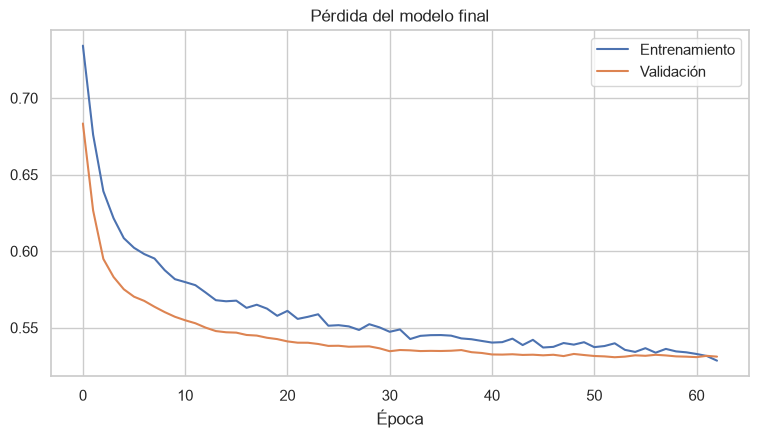

F1 en validación por interés: [0.91  0.372 0.357] | promedio: 0.547


In [15]:
print("Configuración final:", config, "| batch:", BATCH)

tf.keras.utils.set_random_seed(42)
modelo_final = crear_modelo(**config)
parada = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
historia_final = modelo_final.fit(X_train_limpio, Y_train, validation_data=(X_val_limpio, Y_val),
                                  epochs=300, batch_size=BATCH, callbacks=[parada], verbose=0)
print("Épocas entrenadas antes de detenerse:", len(historia_final.history["loss"]))
modelo_final.summary()

plt.figure(figsize=(9, 4.5))
plt.plot(historia_final.history["loss"], label="Entrenamiento")
plt.plot(historia_final.history["val_loss"], label="Validación")
plt.title("Pérdida del modelo final"); plt.xlabel("Época"); plt.legend()
plt.show()

f1 = f1_score(Y_val, (modelo_final.predict(X_val_limpio, verbose=0) > 0.5).astype(int), average=None)
print("F1 en validación por interés:", f1.round(3), "| promedio:", f1.mean().round(3))

> **Qué muestra:** el entrenamiento se detuvo solo en la **época 63**. Las líneas de entrenamiento y validación terminan juntas. En validación, la nota F1 es 0,91 (tecnología), 0,37 (moda) y 0,36 (deportes).
>
> **Qué significa:** la red no está memorizando. Y los experimentos mostraron que la configuración del ejemplo de clase **ya era buena**: las otras opciones empataron o dieron peor resultado. Lo que de verdad mejoró el resultado fue **limpiar los datos** y usar la **parada temprana**.
>
> **Qué decidimos y por qué:** esta es nuestra red final: configuración de clase + datos limpios + parada temprana. Ahora toca el examen final.

## 7. El examen final (datos de prueba)

Ahora usamos los clientes de **prueba**, que la red nunca ha visto. Para cada interés, cada respuesta de la red cae en una de 4 casillas:
- **TP (acierto positivo):** el cliente sí tenía el interés y la red dijo "sí". ✔
- **TN (acierto negativo):** no lo tenía y la red dijo "no". ✔
- **FP (falsa alarma):** no lo tenía, pero la red dijo "sí". ✘
- **FN (se le escapó):** sí lo tenía, pero la red dijo "no". ✘

Con esas casillas se calculan tres notas:

| Nota | Fórmula | Qué responde, en simple |
|---|---|---|
| **Precision** | TP / (TP + FP) | De todos los clientes a los que la red les dijo "sí", ¿cuántos realmente tenían el interés? |
| **Recall** | TP / (TP + FN) | De todos los clientes que realmente tenían el interés, ¿a cuántos encontró la red? |
| **F1-score** | 2·P·R / (P + R) | Una sola nota que combina las dos anteriores; solo es alta si ambas lo son. |

En el reporte, las filas que dicen `avg` son promedios de los tres intereses.

              precision    recall  f1-score   support

  Tecnología       0.86      0.87      0.87       174
        Moda       0.51      0.26      0.34       172
    Deportes       0.55      0.28      0.37       177

   micro avg       0.70      0.47      0.56       523
   macro avg       0.64      0.47      0.53       523
weighted avg       0.64      0.47      0.53       523
 samples avg       0.57      0.42      0.46       523



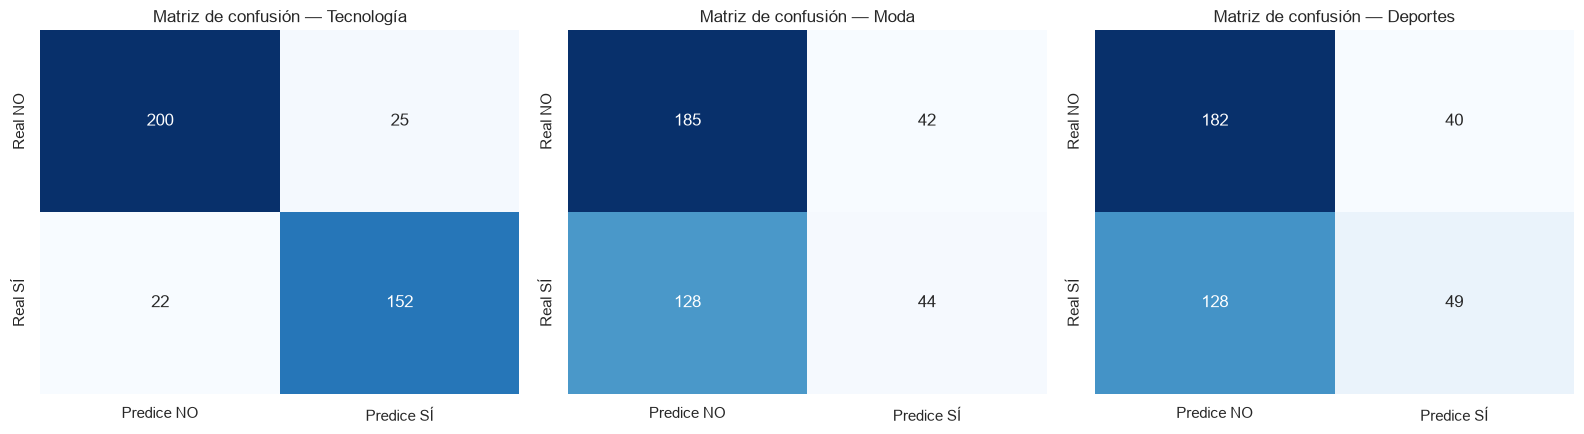

Tecnología → TP=152, FP=25, FN=22, TN=200
Precision = 152/(152+25) = 0.859
Recall    = 152/(152+22) = 0.874


In [16]:
Y_prob = modelo_final.predict(X_test_limpio, verbose=0)
Y_pred = (Y_prob > 0.5).astype(int)          # si la probabilidad pasa de 0.5 → "sí"

print(classification_report(Y_test, Y_pred, target_names=NOMBRES, zero_division=0))

# Una matriz de confusión por interés
matrices = multilabel_confusion_matrix(Y_test, Y_pred)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, ax in enumerate(axes):
    sns.heatmap(matrices[i], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predice NO", "Predice SÍ"], yticklabels=["Real NO", "Real SÍ"])
    ax.set_title(f"Matriz de confusión — {NOMBRES[i]}")
plt.tight_layout()
plt.show()

# Cálculo a mano con Tecnología
tn, fp, fn, tp = matrices[0].ravel()
print(f"Tecnología → TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Precision = {tp}/({tp}+{fp}) = {tp/(tp+fp):.3f}")
print(f"Recall    = {tp}/({tp}+{fn}) = {tp/(tp+fn):.3f}")

> **Qué muestra:** el reporte en texto y tres cuadros (matrices de confusión) con las cuatro casillas de cada interés. En **tecnología**, la precision es 0,86 y el recall 0,87 (F1 **0,87**): de 174 clientes interesados la red encontró 152, y de los 177 a los que dijo "sí" acertó con 152. En **moda** (F1 0,34) y **deportes** (F1 0,37) la precision está entre 0,51 y 0,55, pero el recall es solo **0,26 y 0,28**: la red encuentra apenas a 1 de cada 4 clientes interesados.
>
> **Qué significa:** en tecnología la red funciona muy bien. En moda y deportes casi siempre responde "no", así que se le escapan la mayoría de los interesados. Es lo que esperábamos, porque los datos casi no daban pistas sobre esos dos intereses.
>
> **Qué decidimos y por qué:** no cambiar nada más. Con estos datos no se puede mejorar moda ni deportes; lo correcto es **contarlo con honestidad** y explicar la causa.

### ¿La red es mejor que adivinar?

La comparamos con un **modelo "tonto"** que le dice **"sí" a todos** los clientes en los tres intereses.

También calculamos el **AUC**: una nota entre 0,5 y 1 que dice si la red logra poner más arriba a los clientes que sí tienen el interés que a los que no. **0,5 equivale a lanzar una moneda; 1 es perfecto.**

,F1 modelo tonto,F1 modelo base,F1 modelo final,AUC modelo final
Tecnología,0.607,0.864,0.866,0.951
Moda,0.602,0.320,0.341,0.533
Deportes,0.615,0.408,0.368,0.605


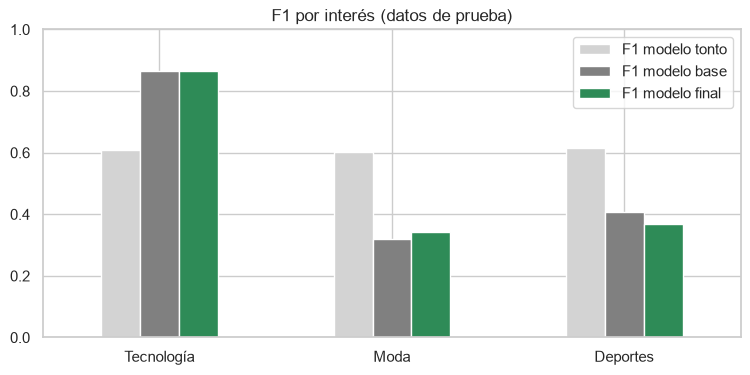

In [17]:
Y_pred_base = (modelo_base.predict(X_test_limpio, verbose=0) > 0.5).astype(int)

comparacion = pd.DataFrame({
    "F1 modelo tonto": f1_score(Y_test, np.ones_like(Y_test), average=None),
    "F1 modelo base": f1_score(Y_test, Y_pred_base, average=None),
    "F1 modelo final": f1_score(Y_test, Y_pred, average=None),
    "AUC modelo final": [roc_auc_score(Y_test[:, i], Y_prob[:, i]) for i in range(3)],
}, index=NOMBRES)
display(comparacion.round(3))

comparacion[["F1 modelo tonto", "F1 modelo base", "F1 modelo final"]].plot(
    kind="bar", rot=0, figsize=(9, 4), color=["lightgray", "gray", "seagreen"], title="F1 por interés (datos de prueba)")
plt.ylim(0, 1)
plt.show()

> **Qué muestra:** una tabla y un gráfico de barras con la nota F1 del modelo tonto (gris claro), la red del ejemplo de clase (gris) y la red final (verde). En **tecnología**, la red final tiene F1 **0,87** contra 0,61 del modelo tonto, y un AUC de **0,95**. En **moda y deportes**, el AUC es **0,53 y 0,61** (casi una moneda) y el modelo tonto tiene mejor F1 (≈ 0,60) que la red (0,34 y 0,37). La red final y la de clase dan resultados parecidos.
>
> **Qué significa:** ¿por qué gana el modelo tonto si no sabe nada? Porque al 44% de los clientes sí le interesa cada tema. Si dices "sí" a todos, encuentras al 100% de los interesados (recall 1,0) y aciertas en el 44% de tus respuestas (precision 0,44); la nota F1 combina esos dos números y da ≈ 0,6. **Es un truco de la nota, no inteligencia.** Por eso miramos también el AUC, que no se deja engañar: en moda y deportes nos dice que la red casi no distingue a los interesados de los que no.
>
> **Qué decidimos y por qué:** concluimos que la red **aprendió bien tecnología**, pero que **moda y deportes no se pueden adivinar con estas 10 columnas**. Ningún ajuste lo arregla: haría falta otra información.

## 8. Conclusiones

### Resumen: qué hicimos, por qué y qué aprendimos

| Etapa | Qué hicimos | Por qué | Qué aprendimos |
|---|---|---|---|
| Datos vacíos | Los rellenamos con la mediana | Borrar filas nos dejaba sin el 40% de los clientes | Rellenar conserva todos los datos |
| Valores extraños | Los marcamos como vacíos y los rellenamos | Valores como −1.584 eran errores y confundían a la red | Limpiar subió el F1 de tecnología de 0,86 a 0,91 y el de moda de 0,16 a 0,38 |
| Respuestas de la red | 3 neuronas sigmoid (una por interés) | Un cliente puede tener varios intereses a la vez | Softmax obligaría a elegir solo uno |
| Learning rate | 0,001 | Pasos ni muy grandes (se pasa de largo) ni muy chicos (muy lento) | Con 0,1 la red dejó de acertar moda |
| Batch | 32 | Las opciones dieron casi lo mismo | No influye mucho en este problema |
| Épocas | Parada temprana (EarlyStopping) | Desde la época 70 la red empieza a memorizar | Se detiene sola en el mejor momento |
| Activación | ReLU | tanh se aplana y la red aprende más lento | ReLU fue mejor en los tres intereses |
| Medida del error | binary_crossentropy | Está hecha para preguntas de sí/no | MSE dio peor resultado en moda |
| Regularización | Dropout 0,2 + L2 0,001 | Sin ella la red memorizaba desde la época 10 | Mantiene juntas las curvas de entrenamiento y validación |
| Capas | 2 capas (64 y 32 neuronas) | 3 capas casi no mejoran | Una red más grande no siempre es mejor |

### Resultado final (examen con datos de prueba)
- **Tecnología:** F1 **0,87** y AUC **0,95**. La red funciona muy bien para este interés.
- **Moda y deportes:** F1 de 0,34 y 0,37, y AUC cerca de 0,5. La red casi no supera al azar.

### La lección principal
Una red neuronal **no puede inventar información que no está en los datos**. Probamos varias configuraciones y ninguna mejoró de verdad moda y deportes, porque las 10 columnas casi no se relacionan con esos intereses. Lo que más mejoró el resultado fue **limpiar bien los datos**, no cambiar la red. En Deep Learning, preparar bien los datos es tan importante como elegir bien la red.

### Qué haríamos para mejorar
- Conseguir **datos nuevos** que sí se relacionen con moda y deportes (por ejemplo, qué categorías de productos visita o compra cada cliente).
- Probar más valores en cada experimento y ajustar el límite de decisión (hoy es 0,5) según qué error sea más costoso para la tienda.